# Experiment 1 — Comparative Evaluation under Limited Historical Data

Persistence, MA(3), Drift, SES và **sMOA N=18.387/k=5/m=4.422**, GAM, omit bridge. Ba training banks trên cùng test set; không ensemble. Synthetic mới **900 curves, 3 test seeds ×3 families ×100**, weekly counts, RNG độc lập; real data dùng historical JHU vintages.

**A:** T=6,8,11 từ reporting onset, origin cũng thay đổi. **B:** T=6,8,11,16,24, cùng origins/targets, chỉ cắt history. Notebook chỉ đọc kết quả; chạy runner trước. Lượt mới dùng **nonconstant_v2, protocol v3**, cùng embed() và kiểm tra mọi row ở cả ba banks. **Holt/ARIMA chạy bằng statsmodels 0.15.0 tại B T16/24**; failures không được thay bằng forecast khác. Notebook kiểm tra hashes rồi đọc duy nhất `outputs/experiment_1_nonconstant_v2/`; report và CSV cùng bộ kết quả, không dùng MAE v1.

In [1]:
from pathlib import Path
import json,sqlite3,hashlib
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'experiments/comparison/experiment_1.py').exists():
    if ROOT==ROOT.parent: raise RuntimeError('Project root not found')
    ROOT=ROOT.parent
OUT=ROOT/'outputs/experiment_1_nonconstant_v2'
progress=json.loads((OUT/'progress.json').read_text())
assert progress['status']=='complete' and progress['primary_complete']
protocol=json.loads((OUT/'protocol.json').read_text())
assert protocol['rules']['version']==3 and protocol['rules']['window_filter']=='nonconstant_v2'
assert progress['protocol_version']==3 and progress['window_filter']=='nonconstant_v2' and progress['inputs_unchanged']
assert hashlib.sha256(protocol['source'].encode()).hexdigest()==progress['analysis_source_sha256']
for relative,expected in progress['artifacts_sha256'].items():
    with (OUT/relative).open('rb') as handle:
        assert hashlib.file_digest(handle,'sha256').hexdigest()==expected, relative
rules_digest=hashlib.sha256(json.dumps(protocol['rules']['embedding'],sort_keys=True).encode()).hexdigest()
assert all(v['embedding_audit']['rules_sha256']==rules_digest and v['rows']==v['embedding_audit']['verified_rows']
           for v in progress['training_banks'].values())
print('Verified run:',OUT,'protocol v3',protocol['engine_signature'])
print('Packages:',protocol['packages'])
print('Zero-selection audit:',progress['test_selection_audit'])
display(pd.DataFrame([dict(seed=s,windows=v['rows'],verified_rows=v['embedding_audit']['verified_rows'],
                          rules_hash=v['embedding_audit']['rules_sha256']) for s,v in progress['training_banks'].items()]))
scores=pd.read_csv(OUT/'scores.csv');pairs=pd.read_csv(OUT/'paired_comparisons.csv')
availability=pd.read_csv(OUT/'availability.csv');runtime=pd.read_csv(OUT/'runtime.csv')
overall=scores.loc[scores.scope.eq('primary_common') & scores.statistic.eq('mean') & scores.dimension.eq('overall')]
db=sqlite3.connect(f"file:{OUT/'results.sqlite'}?mode=ro",uri=True)
print(f"Primary forecasts: {progress['primary_predictions']:,}; history cases: {progress['cases']:,}; fresh test curves: {progress['test_curves']}")
print('Secondary:',progress['secondary_status'])
print('Primary failures:',progress['primary_failures'],'; test/training content collisions:',progress['test_training_hash_collisions'])


Verified run: /Users/nguyentranglinh/infectious-disease-forecasting/outputs/experiment_1_nonconstant_v2 protocol v3 7d2eb5bf4738cef52aaf3f8e4f711e13e66b4ff1cbc5b608f27ea9670db330a0
Packages: {'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'statsmodels': '0.15.0', 'patsy': '1.0.3', 'formulaic': '1.2.2', 'wrapt': '2.6.0.dev1'}
Zero-selection audit: {'attempts': 7200, 'exact_zero_attempts': 0, 'otherwise_eligible_zero_curves': 0, 'selected_zero_curves': 0, 'selected_floor_curves': 775, 'selected_ids_changed_vs_legacy_zero_gate': 0, 'rejection_counts': {'proportion': 2989, 'eligible': 2930, 'monthly': 1142, 'generator_rejected': 137, 'insufficient_followup': 2}, 'generator_floor': 1e-10, 'zero_policy': 'allow zero; reject negative or nonfinite', 'scope': 'weekly-count episodes with raw onset>=10 and 28 steps follow-up; not all generator outputs'}


,seed,windows,verified_rows,rules_hash
0,0,12921078,12921078,5207449c857e0a2d32f9f63f9441ad9d66a34ff972250e...
1,1,12895737,12895737,5207449c857e0a2d32f9f63f9441ad9d66a34ff972250e...
2,2,12901046,12901046,5207449c857e0a2d32f9f63f9441ad9d66a34ff972250e...


Primary forecasts: 464,800; history cases: 16,600; fresh test curves: 900
Secondary: evaluated_with_failures
Primary failures: 0 ; test/training content collisions: 0


## E1.A — Early-stage forecasting

Reporting onset = first weekly count ≥10. Real onset được đóng băng bằng snapshot 04/04/2020, đã biết trước mọi forecast issuance. Models chỉ nhận T observations từ onset. Khi T tăng, target event và epidemic phase cũng đổi: A không tách riêng được tác động của thêm history.

,domain,T,model,n,MAE,RMSE,bias,normalized_MAE,MASE
0,real,6,Drift,200,2970.145000,10722.969831,2584.585000,0.753465,2.411555
11,real,6,MA3,200,1661.965000,4097.743403,96.058333,0.775012,2.452648
22,real,6,Persistence,200,1643.215000,5151.127263,468.825000,0.644507,2.074549
33,real,6,SES,200,1642.440812,5151.110512,469.467330,0.632378,2.050365
77,real,8,Drift,200,2552.096429,7199.829151,2443.352143,0.517417,2.096893
88,real,8,MA3,200,1913.115000,5932.676347,1073.968333,0.391525,1.523516
99,real,8,Persistence,200,1401.735000,4250.421590,968.875000,0.338953,1.270997
110,real,8,SES,200,1400.800669,4250.147296,973.313072,0.337931,1.271013
154,real,11,Drift,200,2014.871000,3777.245323,679.209000,0.999179,3.187005
165,real,11,MA3,200,2068.403333,3932.686580,115.536667,1.056372,3.330263


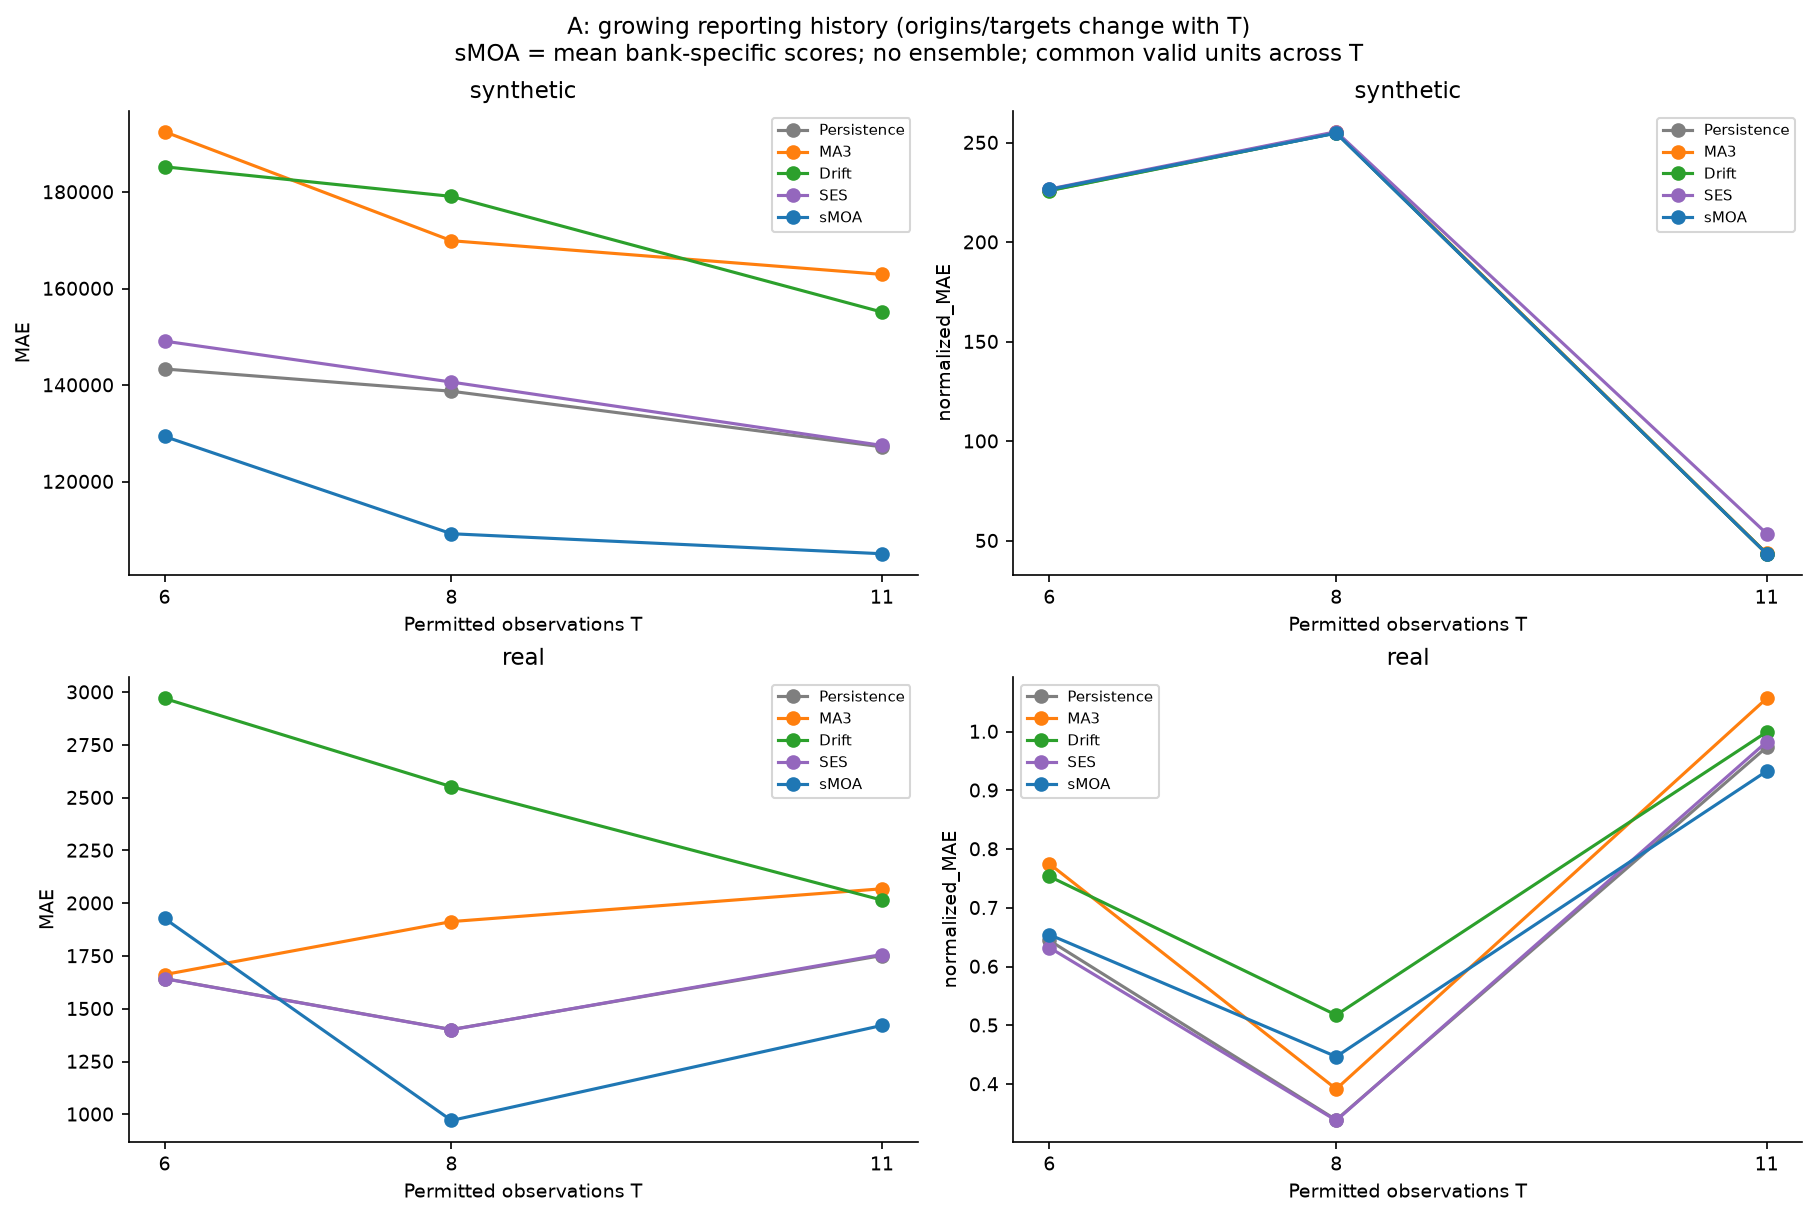

In [2]:
display(overall.loc[overall.arm.eq('A'),['domain','T','model','n','MAE','RMSE','bias','normalized_MAE','MASE']])
display(Image(filename=str(OUT/'figures/early_stage.png')))


## E1.B — Fixed-origin historical availability

Real: 50 states ×37 common origins. Synthetic: fixed origin at reporting age 24. Mỗi origin được cấp last T observations, targets giữ nguyên. Persistence/MA3 phải không đổi qua T. GAM của sMOA fit toàn bộ permitted history rồi mới lấy 6 fitted levels cuối; vì thế T vẫn có thể thay query.

Raw và normalized MAE có thể xếp hạng khác nhau; report giữ cả hai. Synthetic normalized mean rất nhạy với một số future spikes sau history có mức ca thấp; không loại các cases này hoặc đổi metric sau khi thấy kết quả.

,domain,T,model,n,MAE,RMSE,normalized_MAE,MAE_seed_sd
231,real,6,Drift,7400,9009.847541,36033.562235,0.701258,NaN
242,real,6,MA3,7400,8809.703288,30555.638470,0.729665,NaN
253,real,6,Persistence,7400,7460.576622,27677.984955,0.639823,NaN
264,real,6,SES,7400,7571.751245,27835.384485,0.645123,NaN
308,real,8,Drift,7400,8825.545483,33670.892149,0.721989,NaN
319,real,8,MA3,7400,8809.703288,30555.638470,0.729665,NaN
330,real,8,Persistence,7400,7460.576622,27677.984955,0.639823,NaN
341,real,8,SES,7400,7503.930767,27633.475437,0.643122,NaN
385,real,11,Drift,7400,8821.146027,32130.850116,0.751692,NaN
396,real,11,MA3,7400,8809.703288,30555.638470,0.729665,NaN


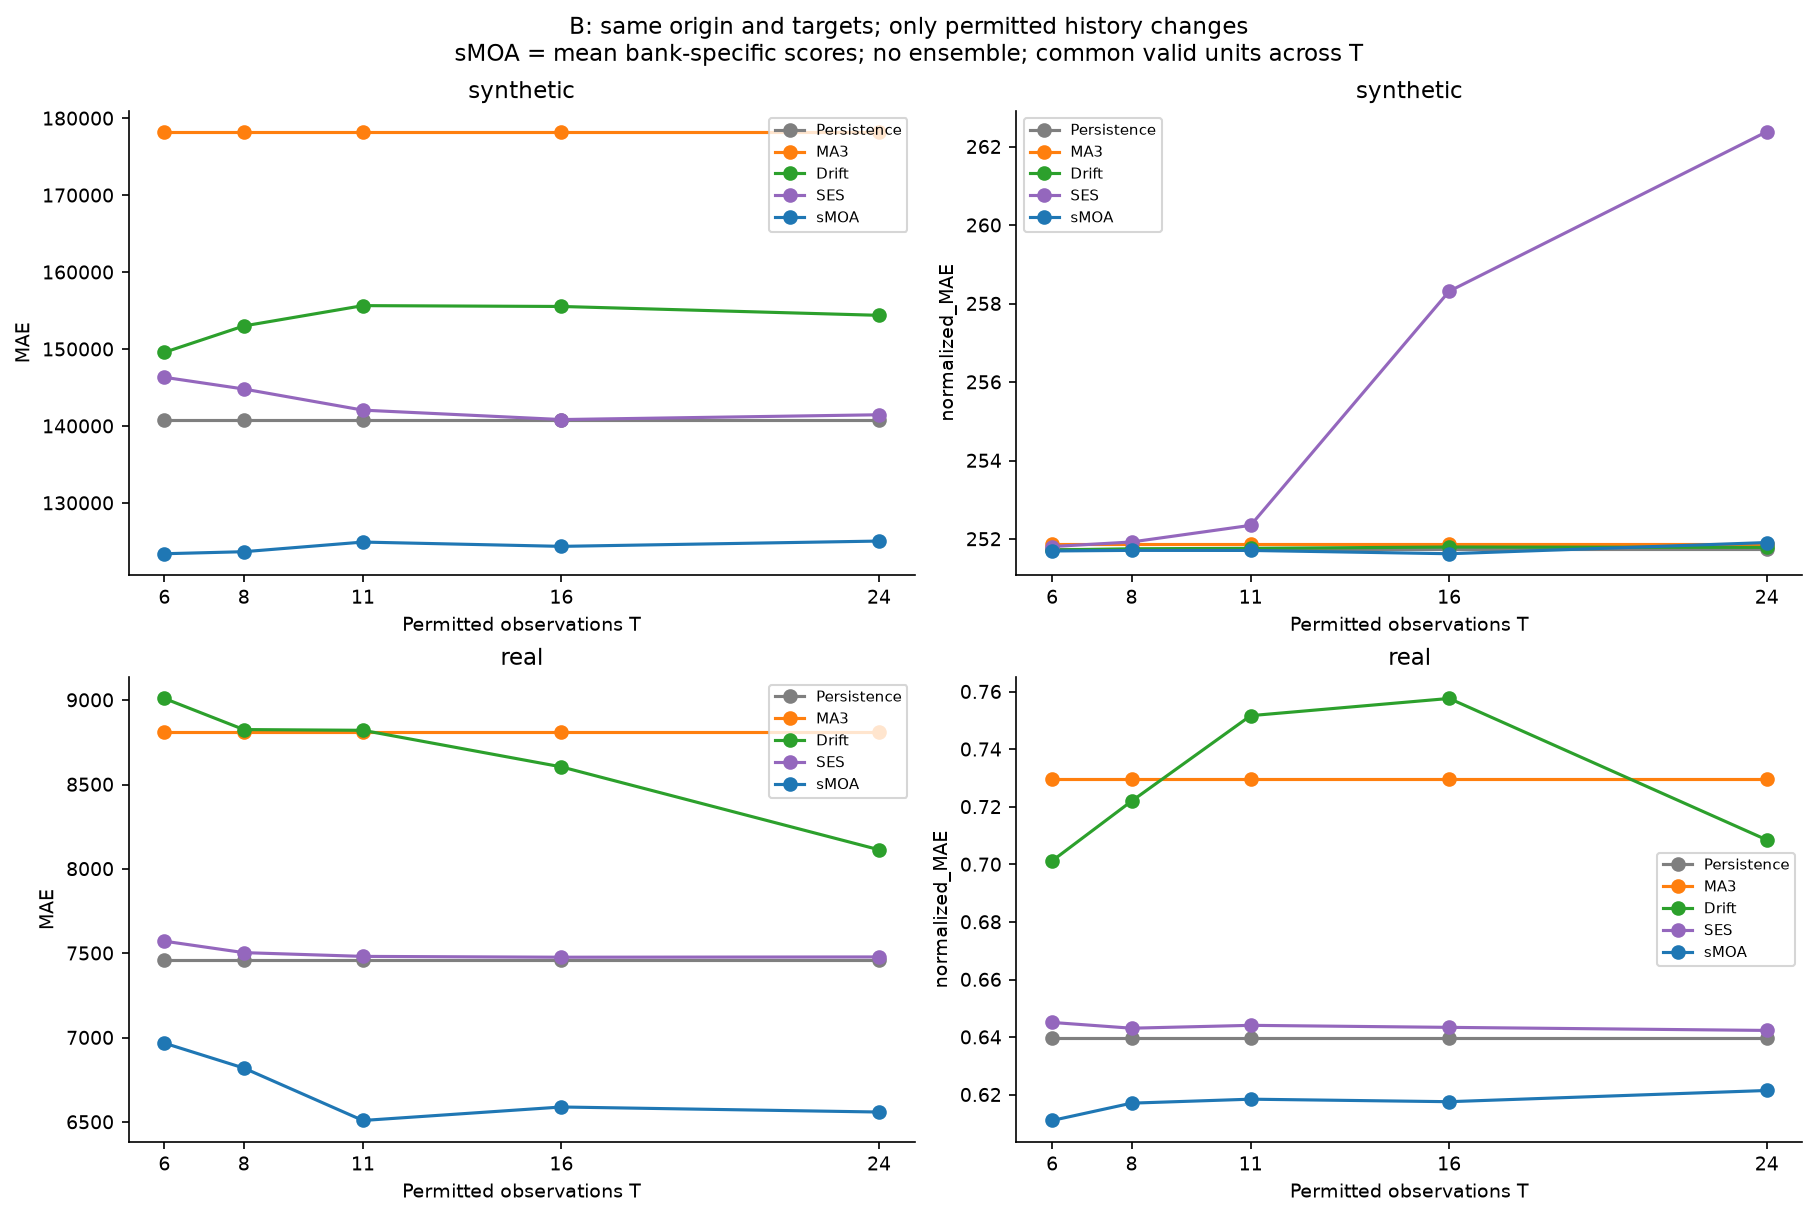

,domain,baseline,delta_MAE,lo,hi
1060,real,Drift,-896.430707,-1246.104980,-601.661409
1061,real,MA3,0.000000,0.000000,0.000000
1062,real,Persistence,0.000000,0.000000,0.000000
1063,real,SES,-93.387686,-248.102802,40.931302
1064,real,sMOA,-408.127534,-707.192282,-187.264624
1065,synthetic,Drift,4809.976884,-11527.894724,20525.855772
1066,synthetic,MA3,0.000000,0.000000,0.000000
1067,synthetic,Persistence,0.000000,0.000000,0.000000
1068,synthetic,SES,-4870.772038,-13517.028982,416.390216
1069,synthetic,sMOA,1646.900036,-669.880085,4735.813393


B query vectors different from T6: 99.16%
Synthetic normalized-loss tail diagnostic: {'mean': 251.69578976431214, 'median': 0.31997642184840924, 'p95': 17.460726002250226, 'p99': 480.7715032679714, 'top_one_percent_share': 0.9817954581244476, 'unit_scale_cases': 77}


In [3]:
display(overall.loc[overall.arm.eq('B'),['domain','T','model','n','MAE','RMSE','normalized_MAE','MAE_seed_sd']])
display(Image(filename=str(OUT/'figures/fixed_origin_history.png')))
display(pairs.loc[pairs.scope.eq('history_24_minus_6'),['domain','baseline','delta_MAE','lo','hi']])
print('B query vectors different from T6:',f"{progress['B_queries_different_from_T6']:.2%}")

print('Synthetic normalized-loss tail diagnostic:', progress['synthetic_B6_normalized_loss_diagnostic'])


## RQ2 bổ sung — Holt và ARIMA tại T=16,24

Chỉ đọc all-secondary common cases: cùng units, hai T, mọi primary model và cả hai mô hình bổ sung đều fit hợp lệ. Pairwise scopes được lưu riêng; không so các MAE khác mẫu. Gap change là `(MAE_sMOA − MAE_model) ở T24` trừ cùng gap ở T16; CI resample nguyên curve/bang. Scope này không đánh giá ARIMA/Holt ở T=6,8,11 hoặc toàn bộ họ ETS/SARIMA.

In [4]:
secondary=scores.loc[scores.scope.eq('all_secondary_common') & scores.statistic.eq('mean') & scores.dimension.eq('overall')]
display(secondary[['domain','T','model','n','MAE','RMSE','normalized_MAE','MASE']])
display(pairs.loc[pairs.scope.eq('secondary_gap_24_minus_16'),['domain','baseline','n','delta_MAE','lo','hi']])
print('Secondary common cases:',progress['secondary_common_cases'])
display(pd.DataFrame(progress['secondary_counts']))

,domain,T,model,n,MAE,RMSE,normalized_MAE,MASE
2352,real,16,ARIMA,7380,8323.158749,29038.052787,0.758102,3.415603
2363,real,16,Drift,7380,8622.210099,30960.500482,0.758198,3.389150
2374,real,16,Holt,7380,8614.385809,32250.005200,0.747383,3.450355
2385,real,16,MA3,7380,8826.191960,30596.492395,0.730389,3.623801
2396,real,16,Persistence,7380,7475.188347,27715.122845,0.640652,3.158147
2407,real,16,SES,7380,7491.397557,27714.546439,0.644250,3.165349
2451,real,24,ARIMA,7380,7825.317542,27396.653392,0.707183,3.461141
2462,real,24,Drift,7380,8129.945570,29356.486519,0.709359,3.436143
2473,real,24,Holt,7380,8351.087521,32396.093885,0.704013,3.557789
2484,real,24,MA3,7380,8826.191960,30596.492395,0.730389,3.798210


,domain,baseline,n,delta_MAE,lo,hi
1056,real,Holt,7380,232.744581,67.201005,384.199490
1057,synthetic,Holt,3528,5931.728562,-2620.578247,14922.232423
1058,real,ARIMA,7380,467.287499,273.097938,697.077721
1059,synthetic,ARIMA,3528,7051.373717,-276.888330,15663.226508


Secondary common cases: 5454


,model,eligible_blocks,valid_blocks,fit_failed,no_valid_candidate,dependency_missing
0,ARIMA,5500,5483,0,17,0
1,Holt,5500,5494,6,0,0


## Forecast horizon

Các ô dưới là normalized MAE ở B, T=6/24, từng horizon. Labels là giá trị thực; mỗi panel có color range riêng. Các T còn lại và raw metrics nằm trong CSV. Không gộp synthetic và real thành một raw MAE.

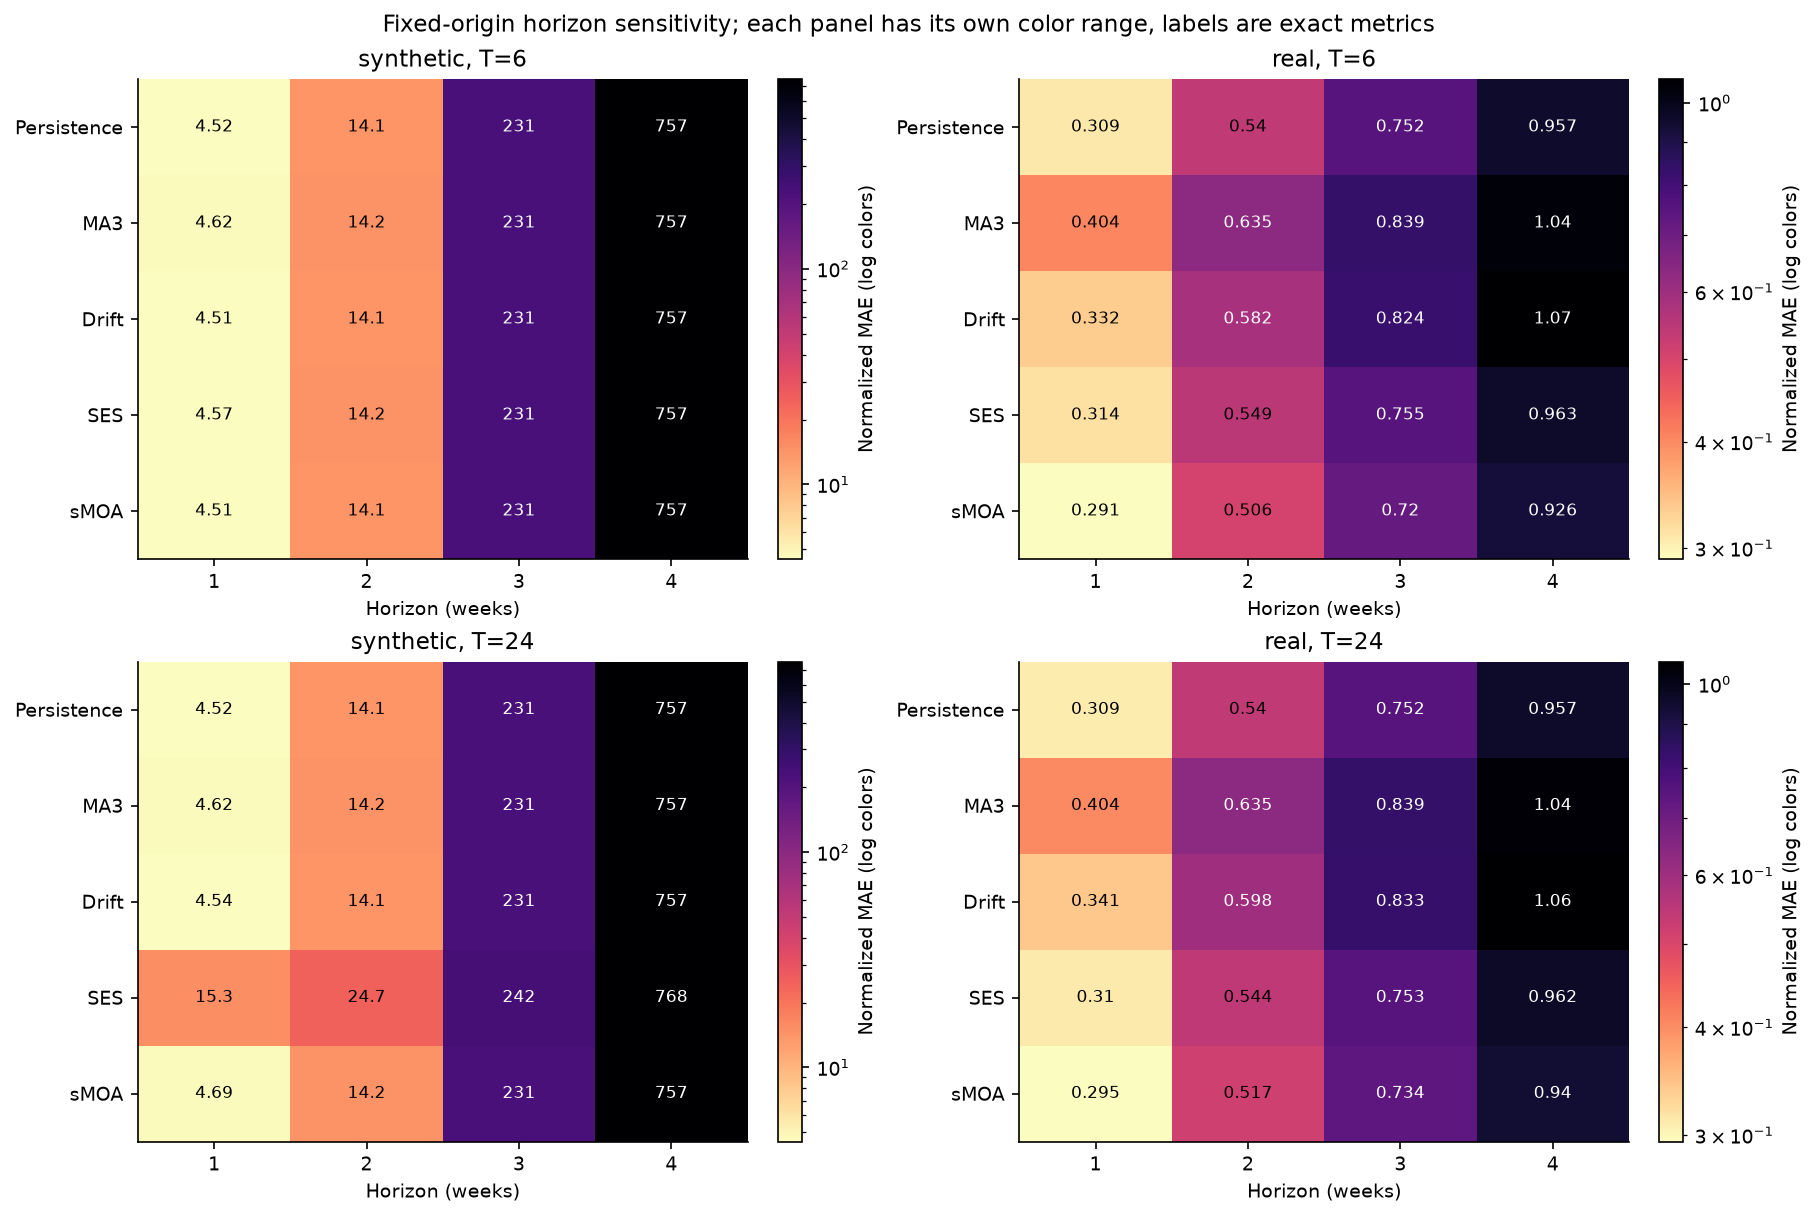

,T,model,group,n,MAE,RMSE,normalized_MAE
232,6,Drift,1,1850,4704.585189,16162.004695,0.332365
233,6,Drift,2,1850,7994.889946,30955.698539,0.582273
234,6,Drift,3,1850,10824.826811,41412.653038,0.824072
235,6,Drift,4,1850,12515.088216,47531.010192,1.066323
243,6,MA3,1,1850,5488.462342,17706.948030,0.404141
...,...,...,...,...,...,...,...
1640,16,sMOA,4,1850,8396.180887,28409.590972,0.932754
1648,24,sMOA,1,1850,3756.032523,12316.591806,0.294915
1649,24,sMOA,2,1850,6182.132613,22740.428130,0.517151
1650,24,sMOA,3,1850,7946.324414,29130.560676,0.734025


In [5]:
display(Image(filename=str(OUT/'figures/horizon_errors.png')))
display(scores.loc[scores.statistic.eq('mean') & scores.scope.eq('primary_common') & scores.dimension.eq('horizon') & scores.domain.eq('real') & scores.arm.eq('B'),
    ['T','model','group','n','MAE','RMSE','normalized_MAE']])


## Paired skill và practical equivalence

Mean **losses** qua ba banks tại từng target, không mean/median predictions để ensemble. Bootstrap nguyên synthetic curve hoặc bang, giữ T/horizon và model pairing. Negative relative delta favors sMOA. Vùng ±5% là margin E1 định trước; equivalence cần toàn bộ 95% interval nằm trong vùng này. CI rộng chứa zero không đủ kết luận tương đương.

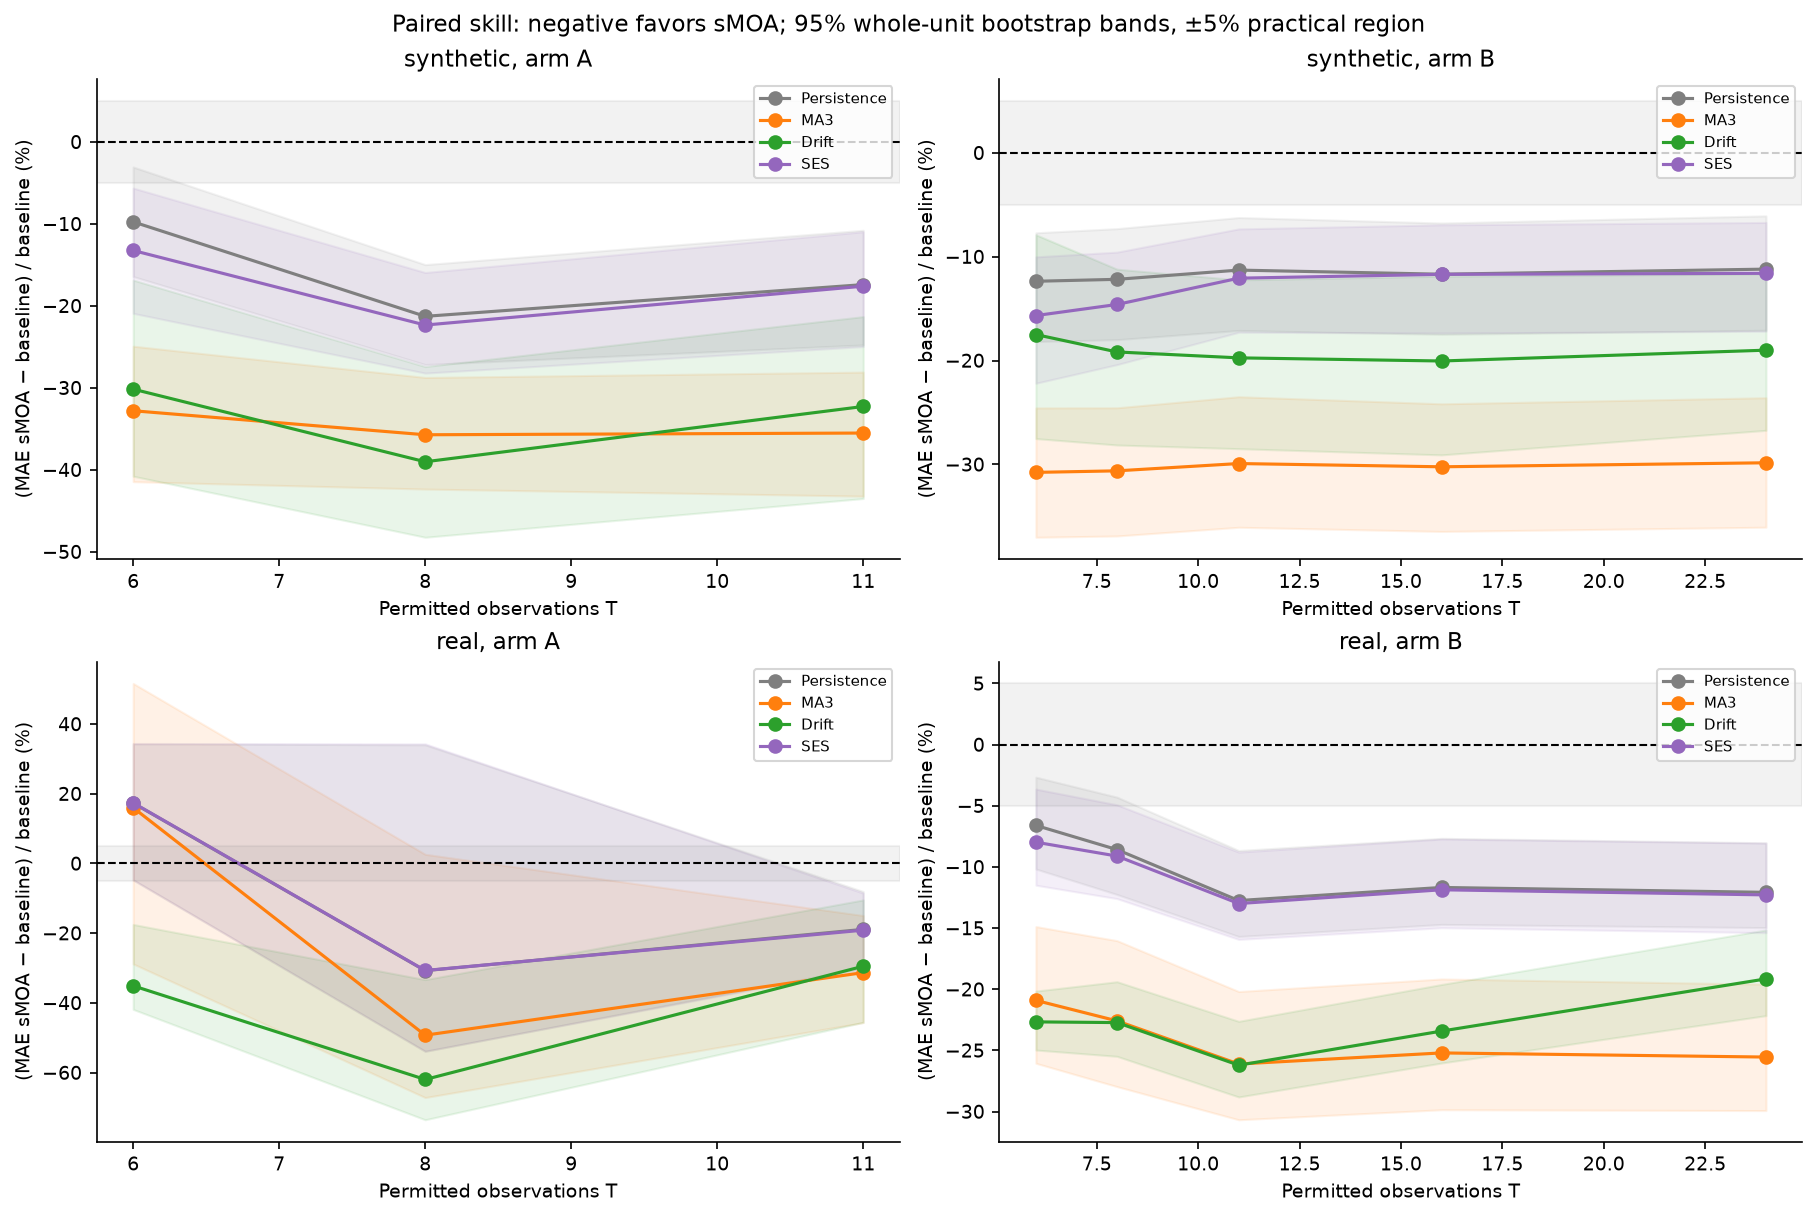

,domain,arm,T,baseline,delta_MAE,lo,hi,relative_delta,relative_lo,relative_hi,practical_equivalence
0,real,A,6,Drift,-1042.344167,-2180.505250,-218.176117,-0.350940,-0.418561,-0.174809,False
11,real,A,6,MA3,265.835833,-402.876229,1104.188208,0.159953,-0.288042,0.516469,False
22,real,A,6,Persistence,284.585833,-52.602729,658.677187,0.173188,-0.047054,0.343254,False
33,real,A,6,SES,285.360022,-52.876225,659.808908,0.173741,-0.047346,0.344151,False
44,real,A,8,Drift,-1581.333095,-3136.540881,-406.221173,-0.619621,-0.735160,-0.333190,False
...,...,...,...,...,...,...,...,...,...,...,...
649,synthetic,B,16,SES,-16481.746455,-23846.814229,-9681.405131,-0.117008,-0.173488,-0.069295,False
660,synthetic,B,24,Drift,-29339.995377,-41754.546057,-18259.680899,-0.190018,-0.267210,-0.116584,False
671,synthetic,B,24,MA3,-53206.029974,-67847.873781,-38971.497279,-0.298454,-0.360493,-0.235824,False
682,synthetic,B,24,Persistence,-15770.898493,-23477.690123,-8808.002812,-0.111980,-0.170716,-0.060691,False


In [6]:
display(Image(filename=str(OUT/'figures/paired_skill.png')))
p=pairs.loc[pairs.scope.eq('primary_common') & pairs.dimension.eq('overall')]
display(p[['domain','arm','T','baseline','delta_MAE','lo','hi','relative_delta','relative_lo','relative_hi','practical_equivalence']])


## Availability, missing models và MASE

Main mask yêu cầu mọi primary model và đủ ba sMOA banks, rồi giữ cùng units qua T. MASE undefined nếu mean(abs(diff(permitted floored history)))=0; các cases đó vẫn trong MAE/RMSE. MASE denominator đổi theo T, nên ưu tiên raw/common-origin hoặc last4-normalized errors khi so qua T.

,eligible_blocks,valid_blocks,dependency_missing,fit_failed,no_valid_candidate
model,,,,,
ARIMA,5500,5483,0,0,17
Drift,16600,16600,0,0,0
Holt,5500,5494,0,6,0
MA3,16600,16600,0,0,0
Persistence,16600,16600,0,0,0
SES,16600,16600,0,0,0
sMOA,49800,49800,0,0,0


MASE undefined targets per model/bank: 592
Retained common history cases: 16600


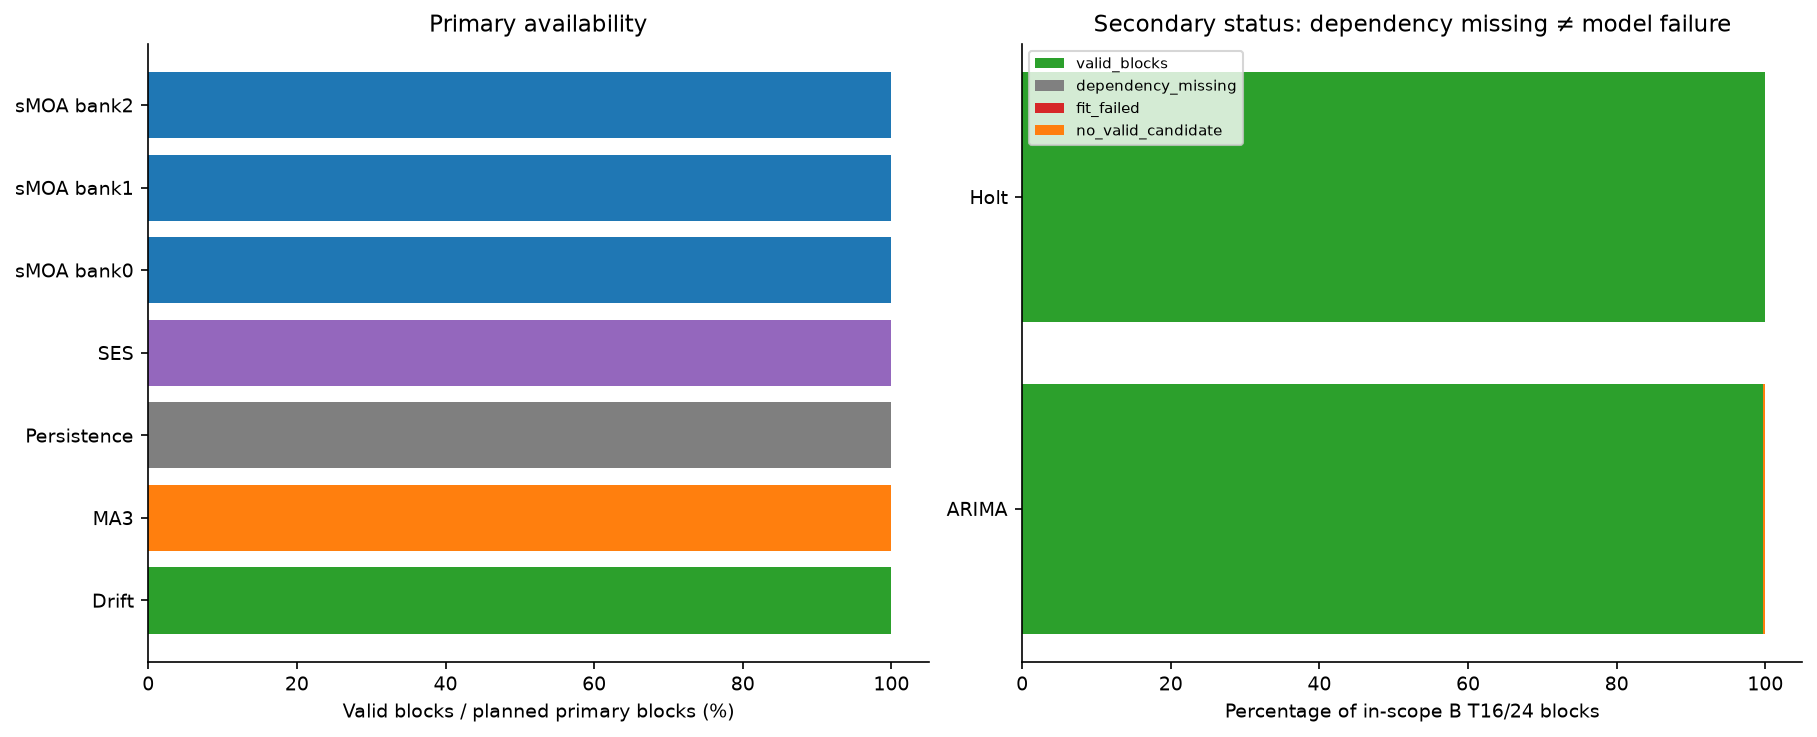

In [7]:
display(availability.groupby('model')[['eligible_blocks','valid_blocks','dependency_missing','fit_failed','no_valid_candidate']].sum())
print('MASE undefined targets per model/bank:',progress['MASE_undefined_targets'])
print('Retained common history cases:',progress['primary_common_cases'])
display(Image(filename=str(OUT/'figures/availability.png')))


## Runtime và kiểm chứng

sMOA online time là tổng GAM cost được charge cho bank và measured batch matching/aggregation: **composed/amortized**, không individual request latency. Query preprocessing thực tế dùng chung. Embedding/index, historical bank generation/replay tách riêng. Baselines gồm fit+predict; dependency-missing models không có runtime estimates. Không xếp hạng từ vài microseconds khác nhau của baselines rất nhanh.

,domain,arm,T,model,bank_seed,kind,cases,seconds,seconds_per_case,timing,peak_rss_bytes
120,all,all,0,sMOA,0,embedding_and_index,0,16.983450,NaN,"same embed() from existing packed bank, indepe...",1.174864e+09
121,all,all,0,sMOA,0,historical_generation_or_replay,0,108.892095,NaN,"historical replay/export, not original generation",NaN
122,all,all,0,sMOA,1,embedding_and_index,0,13.577358,NaN,"same embed() from existing packed bank, indepe...",1.380942e+09
123,all,all,0,sMOA,1,historical_generation_or_replay,0,135.648108,NaN,historical generation/export,NaN
124,all,all,0,sMOA,2,embedding_and_index,0,15.538619,NaN,"same embed() from existing packed bank, indepe...",1.402962e+09
125,all,all,0,sMOA,2,historical_generation_or_replay,0,134.516307,NaN,historical generation/export,NaN
126,all,all,0,GAM shared,-1,shared_query_preprocessing,16600,5.573358,0.000336,"physically computed once, charged to each depl...",NaN


,domain,arm,T,model,bank_seed,kind,cases,seconds,seconds_per_case,timing,peak_rss_bytes
21,real,B,6,Drift,-1,online,1850,0.011868,0.000006,measured fit+prediction,NaN
22,real,B,6,MA3,-1,online,1850,0.013702,0.000007,measured fit+prediction,NaN
23,real,B,6,Persistence,-1,online,1850,0.010690,0.000006,measured fit+prediction,NaN
24,real,B,6,SES,-1,online,1850,0.224394,0.000121,measured fit+prediction,NaN
25,real,B,6,sMOA,0,online,1850,6.641925,0.003590,GAM charged + measured batched search/aggregation,NaN
26,real,B,6,sMOA,1,online,1850,6.415062,0.003468,GAM charged + measured batched search/aggregation,NaN
27,real,B,6,sMOA,2,online,1850,6.308909,0.003410,GAM charged + measured batched search/aggregation,NaN
51,real,B,24,ARIMA,-1,online,1850,35.899134,0.019405,measured fit+prediction,NaN
52,real,B,24,Drift,-1,online,1850,0.011751,0.000006,measured fit+prediction,NaN
53,real,B,24,Holt,-1,online,1850,12.018633,0.006497,measured fit+prediction,NaN


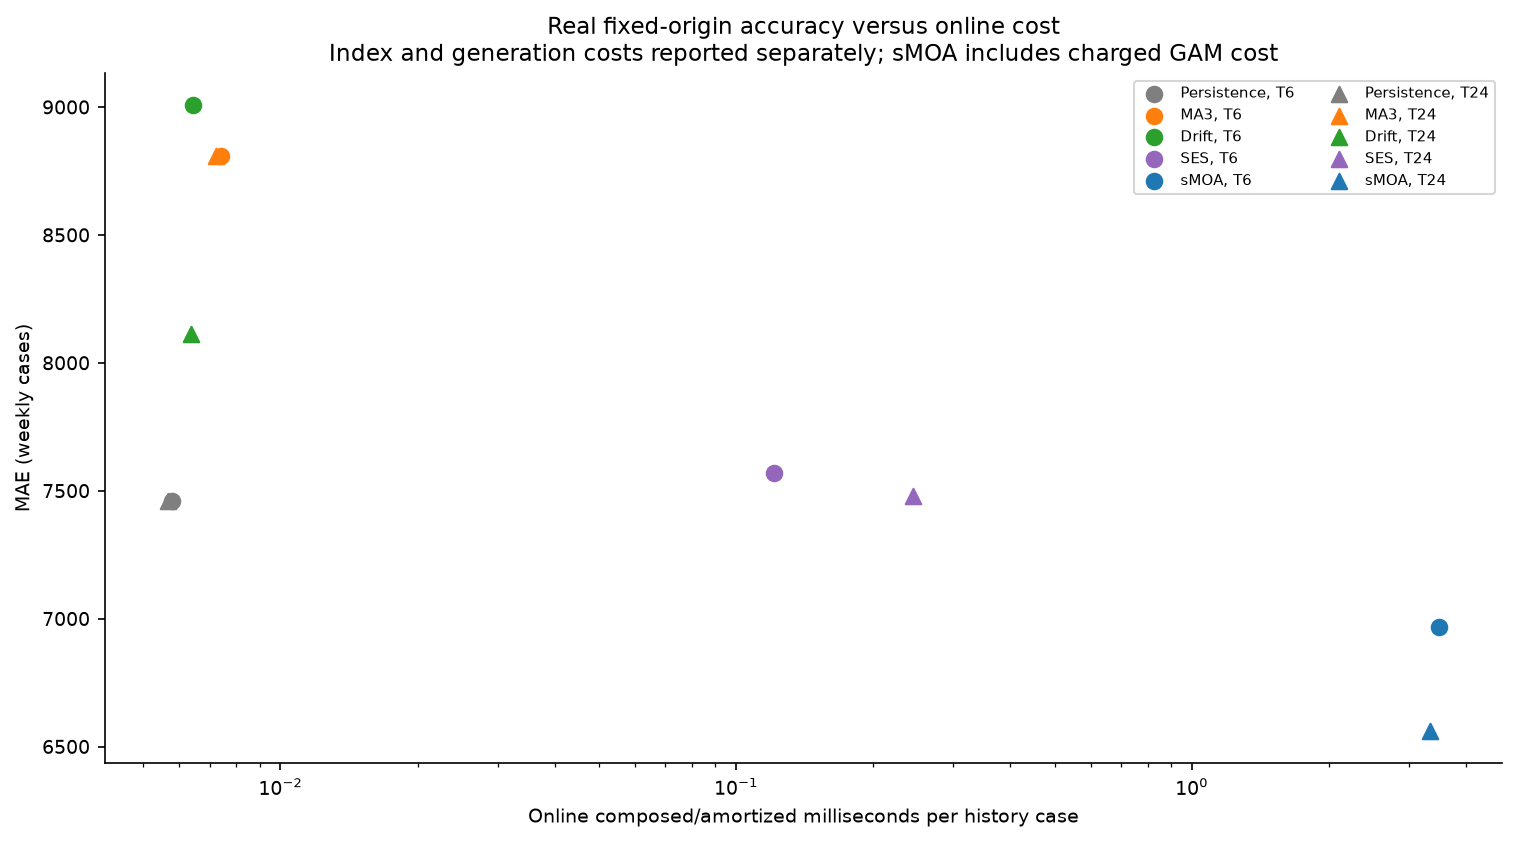

,model,bank_seed,forecasts
0,ARIMA,-1,21932
1,Drift,-1,66400
2,Holt,-1,21976
3,MA3,-1,66400
4,Persistence,-1,66400
5,SES,-1,66400
6,sMOA,0,66400
7,sMOA,1,66400
8,sMOA,2,66400


Verification: {'inputs_unchanged': True, 'fixed_B_targets_verified': True, 'fixed_persistence_MA3_B_verified': True}


In [8]:
display(runtime.loc[runtime.kind.ne('online')])
display(runtime.loc[runtime.kind.eq('online') & runtime.domain.eq('real') & runtime.arm.eq('B') & runtime['T'].isin([6,24])])
display(Image(filename=str(OUT/'figures/error_runtime.png')))
display(pd.read_sql_query('SELECT model,bank_seed,COUNT(*) AS forecasts FROM predictions GROUP BY model,bank_seed',db))
print('Verification:',{k:progress[k] for k in ['inputs_unchanged','fixed_B_targets_verified','fixed_persistence_MA3_B_verified']})
db.close()
